# Iterative Verification and Feedback-Driven Repair of LLM-Generated Counterfactual Explanations
XAI project (Track 2) based on *Can LLMs Explain Themselves Counterfactually?* (EMNLP 2025).

**Setup:** SST-2 dataset, a fixed DistilBERT sentiment classifier, Qwen2.5-3B-Instruct as the generator, LangGraph for the repair loop.

**Methods compared:**
1. One-shot generation (baseline)
2. Multi-candidate selection (baseline)
3. Iterative verification and repair (proposed)
4. Iterative repair with feedback history: the LLM sees all of its earlier failed attempts for the sentence

**Metrics:** validity, edit distance, LLM calls and token usage, plus semantic similarity, fluency, an LLM-judge plausibility score and an actionability rate.

Run with a GPU: Runtime > Change runtime type > T4 GPU.

## Setup : Install dependencies

In [1]:
!pip -q install -U transformers accelerate bitsandbytes datasets langgraph pygraphviz sentence-transformers

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


## Imports & Experiment settings
All the settings are in one place so they are easy to change.
- `N_EVAL`: held-out examples used to compare all methods
- `K`: candidates per example for multi-candidate selection
- `MAX_ATTEMPTS`: retry limit for iterative repair (equal to `K`, so the maximum budgets match)
- `ACTIONABILITY_THRESHOLD`: cutoff score (0.5) for a counterfactual to be actionable
- `ROBUST_CONF`: classifier confidence needed to call a flip robust

In [2]:
import re, time, random, operator
from typing import TypedDict, Annotated, List, Optional

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

SEED = 42
N_EVAL = 200
K = 5
MAX_ATTEMPTS = 5
MAX_NEW_TOKENS = 100
ACTIONABILITY_THRESHOLD = 0.5
ROBUST_CONF = 0.9

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()
print("GPU available:", torch.cuda.is_available())

GPU available: True


## Load SST-2 and the fixed classifier
The classifier is the model being explained. It is never changed. We only use it to check whether a generated counterfactual reaches the target label.

In [3]:
from datasets import load_dataset
from transformers import pipeline

device = 0 if torch.cuda.is_available() else -1

dataset = load_dataset("nyu-mll/glue", "sst2")

classifier = pipeline(
    "text-classification",
    model="distilbert/distilbert-base-uncased-finetuned-sst-2-english",
    device=device,
)

print(dataset)
print(classifier("The movie was engaging and beautifully written."))

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

sst2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

sst2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

sst2/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  148kB            

... (7 outputs left out)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

DatasetDict({
    train: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 67349
    })
    validation: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 872
    })
    test: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 1821
    })
})
[{'label': 'POSITIVE', 'score': 0.999885082244873}]


## Load the generator LLM
Qwen2.5-3B-Instruct in 4-bit, so it fits on a free Colab T4 GPU. This model writes the counterfactuals.

In [4]:
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
llm = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=quant_config,
    device_map="auto",
)
llm.eval()

print("LLM loaded successfully!")

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

LLM loaded successfully!


## Helper functions
- `detokenize`: SST-2 text is pre-tokenized (`it 's`, `do n't`). We turn it back into normal text so the LLM sees natural sentences and edit distance is not inflated by spacing.
- `word_edit_distance`: number of word insertions, deletions and substitutions between the original and the counterfactual (punctuation and case ignored).
- `clean_output`: removes quotes or labels the LLM sometimes adds.
- `predict_sentiment`: asks the fixed classifier for its label and confidence. This is the verification step.

In [5]:
def detokenize(text):
    text = text.strip()
    for a, b in [(" n't", "n't"), (" 's", "'s"), (" 're", "'re"), (" 've", "'ve"),
                 (" 'm", "'m"), (" 'll", "'ll"), (" 'd", "'d")]:
        text = text.replace(a, b)
    text = re.sub(r"\s+([.,!?;:%)\]])", r"\1", text)
    text = re.sub(r"([(\[])\s+", r"\1", text)
    return re.sub(r"\s+", " ", text).strip()

def words(text):
    return re.findall(r"[a-z0-9]+(?:'[a-z]+)?", text.lower())

def word_edit_distance(original, candidate):
    a, b = words(original), words(candidate)
    dp = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]
    for i in range(len(a) + 1):
        dp[i][0] = i
    for j in range(len(b) + 1):
        dp[0][j] = j
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            cost = 0 if a[i - 1] == b[j - 1] else 1
            dp[i][j] = min(dp[i - 1][j] + 1, dp[i][j - 1] + 1, dp[i - 1][j - 1] + cost)
    return dp[-1][-1]

def clean_output(text):
    text = text.strip().split("\n")[0].strip()
    text = re.sub(r"^(rewritten|revised) (review|sentence)?\s*:\s*", "", text, flags=re.I)
    if len(text) > 1 and text[0] in "\"'" and text[-1] in "\"'":
        text = text[1:-1].strip()
    return text

def predict_sentiment(text):
    if not text.strip():
        return "NONE", 0.0
    result = classifier(text, truncation=True)[0]
    return result["label"].upper(), result["score"]

print("Testing Functions ")
print("-------------------")
print(detokenize("it 's a charming and often affecting journey ."))
print(word_edit_distance("The movie was slow.", "The movie was great and fast."))
print(predict_sentiment("The movie was slow and predictable."))

Testing Functions 
-------------------
it's a charming and often affecting journey.
3
('NEGATIVE', 0.9998062252998352)


## Asking the LLM
`ask_llm` sends one prompt to Qwen and returns the answer plus what it cost:
- the cleaned answer text
- number of prompt tokens
- number of new tokens generated
- seconds taken

`sample=False` means greedy decoding (same answer every time). `sample=True` means random sampling, which gives a different answer each call. We need this for multi-candidate selection and for repair attempts.

In [6]:
def ask_llm(prompt, sample=False):
    messages = [
        {"role": "system", "content": "You rewrite movie review sentences."},
        {"role": "user", "content": prompt},
    ]
    text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(llm.device)
    n_prompt = inputs["input_ids"].shape[1]

    start = time.time()
    with torch.no_grad():
        if sample:
            output = llm.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=True,
                                  temperature=0.9, top_p=0.9, pad_token_id=tokenizer.eos_token_id)
        else:
            output = llm.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                                  pad_token_id=tokenizer.eos_token_id)
    seconds = time.time() - start

    new_ids = output[0][n_prompt:]
    answer = clean_output(tokenizer.decode(new_ids, skip_special_tokens=True))
    return answer, n_prompt, len(new_ids), seconds

## Prepare the data
- We sample `N_EVAL` examples from the SST-2 **validation** split with a fixed seed.
- The **target label** is always the opposite of what the classifier predicts for the original sentence. Every method uses the same rule and the same examples.

In [7]:
val = dataset["validation"].to_pandas()

if N_EVAL is not None and N_EVAL < len(val):
    eval_df = val.sample(n=N_EVAL, random_state=SEED).reset_index(drop=True)
else:
    eval_df = val.copy().reset_index(drop=True)

eval_df["id"] = eval_df["idx"]
eval_df["original"] = eval_df["sentence"].map(detokenize)

# Classifier prediction on each original sentence
preds = classifier(eval_df["original"].tolist(), truncation=True, batch_size=32)
eval_df["original_label"] = [p["label"].upper() for p in preds]
eval_df["target_label"] = np.where(eval_df["original_label"] == "NEGATIVE", "POSITIVE", "NEGATIVE")

print("Evaluation examples:", len(eval_df))
print(eval_df["target_label"].value_counts())
eval_df[["id", "original", "original_label", "target_label"]].head()

Evaluation examples: 200
target_label
NEGATIVE    112
POSITIVE     88
Name: count, dtype: int64


,id,original,original_label,target_label
0,794,it confirms fincher's status as a film maker w...,POSITIVE,NEGATIVE
1,319,too much of it feels unfocused and underdevelo...,NEGATIVE,POSITIVE
2,382,a great ensemble cast can't lift this heartfel...,NEGATIVE,POSITIVE
3,779,"prurient playthings aside, there's little to l...",NEGATIVE,POSITIVE
4,422,"it moves quickly, adroitly, and without fuss; ...",POSITIVE,NEGATIVE


## Prompts
All methods use the **same initial prompt**, so differences in results come from the method and not from different wording.

- `initial_prompt`: asks for a rewrite with the target sentiment.
- `repair_prompt`: used only by iterative repair. It shows the LLM its failed candidate and what the classifier predicted, and asks for a revision.
- `guidelines` is optional. It stays empty for all baselines and is filled only in the feedback-memory experiments.

In [8]:
def guideline_text(guidelines):
    if not guidelines:
        return ""
    return f"\nGuidelines learned from earlier failures (apply them where relevant):\n{guidelines}\n"

def initial_prompt(original, target, guidelines=None):
    return (f"Rewrite the movie review sentence so that its sentiment is {target.lower()}.\n"
            "Preserve the original meaning and change as little text as possible.\n"
            "Return only the rewritten sentence.\n"
            f"{guideline_text(guidelines)}\n"
            f"Original review: {original}\n"
            "Rewritten review:")

def repair_prompt(original, target, previous, observed_label, observed_conf, guidelines=None):
    return (f"You rewrote a movie review sentence so that its sentiment would be {target.lower()}, "
            f"but a fixed sentiment classifier predicted {observed_label} "
            f"(confidence {observed_conf:.3f}) for your rewrite.\n\n"
            f"Original review: {original}\n"
            f"Your previous rewrite: {previous}\n\n"
            f"Revise the rewrite so that the classifier predicts {target}. "
            "Preserve the original meaning and change as little text as possible.\n"
            "Return only the revised sentence.\n"
            f"{guideline_text(guidelines)}\n"
            "Revised review:")

print(initial_prompt("the film is slow and dull.", "POSITIVE"))
print("-" * 50)
print(repair_prompt("the film is slow and dull.", "POSITIVE", "the film is slow but fun.", "NEGATIVE", 0.91))

answer, n_prompt, n_new, secs = ask_llm(initial_prompt("The movie was slow and predictable.", "POSITIVE"))
print(answer, "|", n_prompt, "prompt tokens |", n_new, "new tokens |", round(secs, 2), "s")
print(predict_sentiment(answer))

Rewrite the movie review sentence so that its sentiment is positive.
Preserve the original meaning and change as little text as possible.
Return only the rewritten sentence.

Original review: the film is slow and dull.
Rewritten review:
--------------------------------------------------
You rewrote a movie review sentence so that its sentiment would be positive, but a fixed sentiment classifier predicted NEGATIVE (confidence 0.910) for your rewrite.

Original review: the film is slow and dull.
Your previous rewrite: the film is slow but fun.

Revise the rewrite so that the classifier predicts POSITIVE. Preserve the original meaning and change as little text as possible.
Return only the revised sentence.

Revised review:
The movie felt slow and predictable. | 65 prompt tokens | 8 new tokens | 1.22 s
('NEGATIVE', 0.9998106360435486)


## Verification
`verify` is the check at the heart of the project. It sends a candidate to the fixed classifier and records:
- the predicted label and confidence
- whether the prediction equals the target label (`valid`)
- how much the text changed (word edit distance, absolute and relative to the original length)
- `target_confidence`: how much probability the classifier gives to the target label. We use it later to pick the best failed candidate when nothing succeeds.

In [9]:
def verify(original, target, candidate):
    label, conf = predict_sentiment(candidate)

    if label == target:
        target_conf = conf
    elif label == "NONE":
        target_conf = 0.0
    else:
        target_conf = 1 - conf          # binary classifier

    edit = word_edit_distance(original, candidate)

    return {
        "candidate": candidate,
        "predicted_label": label,
        "confidence": conf,
        "target_confidence": target_conf,
        "valid": label == target,
        "edit_distance": edit,
        "rel_edit_distance": edit / max(len(words(original)), 1),
    }

print(verify("The movie was slow and predictable.", "POSITIVE", "The movie was fast and exciting."))

{'candidate': 'The movie was fast and exciting.', 'predicted_label': 'POSITIVE', 'confidence': 0.9998558759689331, 'target_confidence': 0.9998558759689331, 'valid': True, 'edit_distance': 2, 'rel_edit_distance': 0.3333333333333333}


# Baseline 1: One-shot generation (LangGraph)
Each example flows through the graph as one row of data:

`START -> generate -> verify -> save -> END`

- **start**: receives one row (id, original sentence, target label) and sets the counters to zero.
- **generate**: the LLM writes one counterfactual (greedy).
- **verify**: the fixed classifier checks it.
- **save**: appends the result as one line of `one_shot_results.csv`. There is no revision.

All pipelines share one `State` so the later graphs (multi-candidate, iterative, memory) can reuse it.

In [10]:
import os
from langgraph.graph import StateGraph, START, END

class State(TypedDict, total=False):
    # the input row
    id: int
    original: str
    target_label: str
    # the current candidate and its verification
    candidate: str
    predicted_label: str
    confidence: float
    target_confidence: float
    valid: bool
    edit_distance: int
    rel_edit_distance: float
    # cost counters
    llm_calls: int
    prompt_tokens: int
    new_tokens: int
    seconds: float
    saved: bool

def start_node(state):
    return {"candidate": "", "llm_calls": 0, "prompt_tokens": 0, "new_tokens": 0, "seconds": 0.0}

def generate_node(state):
    prompt = initial_prompt(state["original"], state["target_label"])
    answer, n_prompt, n_new, secs = ask_llm(prompt)
    return {"candidate": answer,
            "llm_calls": state["llm_calls"] + 1,
            "prompt_tokens": state["prompt_tokens"] + n_prompt,
            "new_tokens": state["new_tokens"] + n_new,
            "seconds": state["seconds"] + secs}

def verify_node(state):
    return verify(state["original"], state["target_label"], state["candidate"])

SAVE_COLUMNS = ["id", "original", "target_label", "candidate", "predicted_label", "valid",
                "edit_distance", "rel_edit_distance", "llm_calls", "prompt_tokens", "new_tokens", "seconds"]

def save_node(state):
    row = {c: state[c] for c in SAVE_COLUMNS}
    pd.DataFrame([row]).to_csv("one_shot_results.csv", mode="a", index=False,
                               header=not os.path.exists("one_shot_results.csv"))
    return {"saved": True}

g = StateGraph(State)
g.add_node("start", start_node)
g.add_node("generate", generate_node)
g.add_node("verify", verify_node)
g.add_node("save", save_node)
g.add_edge(START, "start")
g.add_edge("start", "generate")
g.add_edge("generate", "verify")
g.add_edge("verify", "save")
g.add_edge("save", END)
one_shot_graph = g.compile()

# print(one_shot_graph.get_graph().draw_mermaid())

In [11]:
# run one-shot on every evaluation example
if os.path.exists("one_shot_results.csv"):
    os.remove("one_shot_results.csv")          # start from a clean file

set_seed()
for _, row in tqdm(eval_df.iterrows(), total=len(eval_df)):
    one_shot_graph.invoke({"id": int(row["id"]),
                           "original": row["original"],
                           "target_label": row["target_label"]})

res_one = pd.read_csv("one_shot_results.csv")
print(len(res_one), "rows saved")

  0%|          | 0/200 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


200 rows saved


In [12]:
# look at some failures
res_one[~res_one["valid"]][["original", "target_label", "candidate", "predicted_label"]].head(8)

,original,target_label,candidate,predicted_label
0,it confirms fincher's status as a film maker w...,NEGATIVE,it confirms fincher's status as a film maker w...,POSITIVE
1,too much of it feels unfocused and underdevelo...,POSITIVE,too much of it feels unfocused and underdevelo...,NEGATIVE
3,"prurient playthings aside, there's little to l...",POSITIVE,"prurient playthings aside, little to love abou...",NEGATIVE
4,"it moves quickly, adroitly, and without fuss; ...",NEGATIVE,"it moves quickly, adroitly, and without fuss; ...",POSITIVE
5,"it proves quite compelling as an intense, broo...",NEGATIVE,"it proves quite compelling as an intense, broo...",POSITIVE
6,bogdanovich tantalizes by offering a peep show...,NEGATIVE,bogdanovich tantalizes by offering a peep show...,POSITIVE
7,looks and feels like a project better suited f...,POSITIVE,feels and looks like a project better suited f...,NEGATIVE
10,a painfully funny ode to bad behavior.,NEGATIVE,a painfully funny ode to bad behavior.,POSITIVE


In [13]:
def summarize(df, name):
    ok = df[df["valid"]]
    return pd.DataFrame([{
        "Method": name,
        "Validity (%)": 100 * df["valid"].mean(),
        "Edit distance (valid)": ok["edit_distance"].mean(),
        "Relative edit (valid)": ok["rel_edit_distance"].mean(),
        "LLM calls / example": df["llm_calls"].mean(),
        "Tokens / example": (df["prompt_tokens"] + df["new_tokens"]).mean(),
        "Seconds / example": df["seconds"].mean(),
    }]).round(2)

summarize(res_one, "One-shot")

,Method,Validity (%),Edit distance (valid),Relative edit (valid),LLM calls / example,Tokens / example,Seconds / example
0,One-shot,39.5,6.46,0.41,1.0,104.56,2.18


# Baseline 2: Multi-candidate selection (LangGraph)
Instead of trusting one generation, we sample **K = 5** independent candidates for each sentence, verify all of them, and keep the best one.

`START -> generate_k -> select -> save -> END`

- **generate_k**: a `for` loop calls the LLM K times (random sampling, so each answer is different) and verifies each candidate with the fixed classifier.
- **select**: among the **valid** candidates, keep the one with the **smallest edit distance**. If none is valid, the example counts as a failure (we only keep the closest candidate so we can inspect it).
- **save**: writes the result to `multi_candidate_results.csv`.

Cost note: K separate LLM calls are made, so calls and tokens are about K times those of one-shot. This is the price of this baseline.

In [14]:
class MultiState(State):
    candidates: list            # every verified candidate for this example
    n_valid_candidates: int

def generate_k_node(state):
    candidates = []
    calls, p_tokens, n_tokens, secs = state["llm_calls"], state["prompt_tokens"], state["new_tokens"], state["seconds"]

    for i in range(K):
        prompt = initial_prompt(state["original"], state["target_label"])
        answer, n_prompt, n_new, s = ask_llm(prompt, sample=True)
        candidates.append(verify(state["original"], state["target_label"], answer))
        calls += 1
        p_tokens += n_prompt
        n_tokens += n_new
        secs += s

    return {"candidates": candidates, "llm_calls": calls,
            "prompt_tokens": p_tokens, "new_tokens": n_tokens, "seconds": secs}

def select_node(state):
    valid = [c for c in state["candidates"] if c["valid"]]
    if valid:
        best = min(valid, key=lambda c: c["edit_distance"])      # smallest change among valid
    else:
        best = max(state["candidates"], key=lambda c: c["target_confidence"])   # closest failure
    return {**best, "n_valid_candidates": len(valid)}

MULTI_COLUMNS = SAVE_COLUMNS + ["n_valid_candidates"]

def save_multi_node(state):
    row = {c: state[c] for c in MULTI_COLUMNS}
    pd.DataFrame([row]).to_csv("multi_candidate_results.csv", mode="a", index=False,
                               header=not os.path.exists("multi_candidate_results.csv"))
    return {"saved": True}

g = StateGraph(MultiState)
g.add_node("start", start_node)
g.add_node("generate_k", generate_k_node)
g.add_node("select", select_node)
g.add_node("save", save_multi_node)
g.add_edge(START, "start")
g.add_edge("start", "generate_k")
g.add_edge("generate_k", "select")
g.add_edge("select", "save")
g.add_edge("save", END)
multi_graph = g.compile()

# print(multi_graph.get_graph().draw_mermaid())

In [15]:
if os.path.exists("multi_candidate_results.csv"):
    os.remove("multi_candidate_results.csv")

set_seed()
for _, row in tqdm(eval_df.iterrows(), total=len(eval_df)):
    multi_graph.invoke({"id": int(row["id"]),
                        "original": row["original"],
                        "target_label": row["target_label"]})

res_multi = pd.read_csv("multi_candidate_results.csv")
print(len(res_multi), "rows saved")

  0%|          | 0/200 [00:00<?, ?it/s]

200 rows saved


In [16]:
pd.concat([summarize(res_one, "One-shot"),
           summarize(res_multi, f"Multi-candidate (K={K})")], ignore_index=True)

,Method,Validity (%),Edit distance (valid),Relative edit (valid),LLM calls / example,Tokens / example,Seconds / example
0,One-shot,39.5,6.46,0.41,1.0,104.56,2.18
1,Multi-candidate (K=5),59.5,5.24,0.33,5.0,523.26,10.87


In [17]:
# how many of the K candidates were valid per example, and which examples still failed
print(res_multi["n_valid_candidates"].value_counts().sort_index())
res_multi[~res_multi["valid"]][["original", "target_label", "candidate", "predicted_label"]].head(8)

n_valid_candidates
0    81
1    20
2    16
3    22
4    13
5    48
Name: count, dtype: int64


,original,target_label,candidate,predicted_label
3,"prurient playthings aside, there's little to l...",POSITIVE,"prurient playthings aside, little to love abou...",NEGATIVE
4,"it moves quickly, adroitly, and without fuss; ...",NEGATIVE,"it moves quickly, adroitly, and without fuss; ...",POSITIVE
5,"it proves quite compelling as an intense, broo...",NEGATIVE,"it proves quite compelling as an intense, broo...",POSITIVE
18,"the last 20 minutes are somewhat redeeming, bu...",POSITIVE,"The last 20 minutes are somewhat redeeming, bu...",NEGATIVE
21,"yes, dull.",POSITIVE,"yes, dull.",NEGATIVE
22,"shaky close-ups of turkey-on-rolls, stubbly ch...",POSITIVE,"shaky close-ups of turkey-on-rolls, stubbly ch...",NEGATIVE
25,"nonsensical, dull `` cyber-horror '' flick is ...",POSITIVE,"The ``cyber-horror'' flick is a grim, hollow e...",NEGATIVE
27,thanks to scott's charismatic roger and eisenb...,NEGATIVE,thanks to scott's charismatic roger and eisenb...,POSITIVE


# Proposed method: Iterative verification and repair (LangGraph)
Instead of accepting the first output, we verify it and, if the classifier does not predict the target label, send the failed candidate back to the LLM together with what the classifier said. The LLM revises, we verify again, and so on until success or the retry limit (`MAX_ATTEMPTS`).

```
START -> generate -> verify ─┬─ valid, or attempts = MAX_ATTEMPTS -> save -> END
                             └─ otherwise -> repair -> verify (loop)
```

- **generate**: first attempt, greedy decoding and the same prompt as one-shot. So the first-attempt validity must equal the one-shot validity, and any improvement comes from repair alone.
- **verify**: fixed classifier check. It also counts the attempt.
- **route** (conditional edge): decides whether to stop or repair.
- **repair**: sees only the **previous candidate** and the **classifier's prediction and confidence** for it. It then writes a revision (sampling, so a retry is not identical to the previous attempt).
- **save**: writes the final result to `iterative_results.csv`.

In [18]:
class IterState(State):
    attempts: int
    first_attempt_valid: bool

def start_iter_node(state):
    return {"candidate": "", "attempts": 0, "llm_calls": 0,
            "prompt_tokens": 0, "new_tokens": 0, "seconds": 0.0}

def generate_iter_node(state):
    prompt = initial_prompt(state["original"], state["target_label"])
    answer, n_prompt, n_new, secs = ask_llm(prompt)              # greedy, same as one-shot
    return {"candidate": answer, "attempts": 1,
            "llm_calls": state["llm_calls"] + 1,
            "prompt_tokens": state["prompt_tokens"] + n_prompt,
            "new_tokens": state["new_tokens"] + n_new,
            "seconds": state["seconds"] + secs}

def verify_iter_node(state):
    result = verify(state["original"], state["target_label"], state["candidate"])
    if state["attempts"] == 1:
        result["first_attempt_valid"] = result["valid"]
    return result

def route_after_verify(state):
    if state["valid"] or state["attempts"] >= MAX_ATTEMPTS:
        return "save"
    return "repair"

def repair_node(state):
    # only the previous output and the classifier's verdict are given to the LLM
    prompt = repair_prompt(state["original"], state["target_label"], state["candidate"],
                           state["predicted_label"], state["confidence"])
    answer, n_prompt, n_new, secs = ask_llm(prompt, sample=True)
    return {"candidate": answer, "attempts": state["attempts"] + 1,
            "llm_calls": state["llm_calls"] + 1,
            "prompt_tokens": state["prompt_tokens"] + n_prompt,
            "new_tokens": state["new_tokens"] + n_new,
            "seconds": state["seconds"] + secs}

ITER_COLUMNS = SAVE_COLUMNS + ["attempts", "first_attempt_valid"]

def save_iter_node(state):
    row = {c: state[c] for c in ITER_COLUMNS}
    pd.DataFrame([row]).to_csv("iterative_results.csv", mode="a", index=False,
                               header=not os.path.exists("iterative_results.csv"))
    return {"saved": True}

g = StateGraph(IterState)
g.add_node("start", start_iter_node)
g.add_node("generate", generate_iter_node)
g.add_node("verify", verify_iter_node)
g.add_node("repair", repair_node)
g.add_node("save", save_iter_node)
g.add_edge(START, "start")
g.add_edge("start", "generate")
g.add_edge("generate", "verify")
g.add_conditional_edges("verify", route_after_verify, {"repair": "repair", "save": "save"})
g.add_edge("repair", "verify")
g.add_edge("save", END)
iterative_graph = g.compile()

# print(iterative_graph.get_graph().draw_mermaid())

In [19]:
if os.path.exists("iterative_results.csv"):
    os.remove("iterative_results.csv")

set_seed()
for _, row in tqdm(eval_df.iterrows(), total=len(eval_df)):
    iterative_graph.invoke({"id": int(row["id"]),
                            "original": row["original"],
                            "target_label": row["target_label"]},
                           config={"recursion_limit": 50})

res_iter = pd.read_csv("iterative_results.csv")
print(len(res_iter), "rows saved")
print("Attempt-1 validity (should equal one-shot):",
      round(100 * res_iter["first_attempt_valid"].mean(), 1), "vs", round(100 * res_one["valid"].mean(), 1))

  0%|          | 0/200 [00:00<?, ?it/s]

200 rows saved
Attempt-1 validity (should equal one-shot): 39.5 vs 39.5


In [20]:
summary = pd.concat([summarize(res_one, "One-shot"),
                     summarize(res_multi, f"Multi-candidate (K={K})"),
                     summarize(res_iter, "Iterative repair")], ignore_index=True)
summary

,Method,Validity (%),Edit distance (valid),Relative edit (valid),LLM calls / example,Tokens / example,Seconds / example
0,One-shot,39.5,6.46,0.41,1.0,104.56,2.18
1,Multi-candidate (K=5),59.5,5.24,0.33,5.0,523.26,10.87
2,Iterative repair,73.0,6.56,0.42,2.6,368.89,5.67


In [21]:
# at which attempt did iterative repair succeed?
print(res_iter[res_iter["valid"]]["attempts"].value_counts().sort_index().to_string())
print("Never valid within the limit:", int((~res_iter["valid"]).sum()))

# # examples that failed first but were repaired
fixed = res_iter[(~res_iter["first_attempt_valid"]) & res_iter["valid"]]
print(f"\n{len(fixed)} examples were repaired")
fixed[["original", "target_label", "candidate", "attempts"]].head(1)

attempts
1    79
2    42
3    17
4     4
5     4
Never valid within the limit: 54

67 examples were repaired


,original,target_label,candidate,attempts
1,too much of it feels unfocused and underdevelo...,POSITIVE,Too much of it feels focused and well-developed.,2


# Iterative repair with feedback history (LangGraph)
In plain iterative repair, the LLM only sees its **previous** output. Here the state keeps a list called `history` with **every failed attempt** for the current sentence: what was written, and what the classifier predicted.

The repair prompt shows the LLM that whole list, so it can see everything it already tried and failed, and avoid repeating it.

```
START -> generate -> verify ─┬─ valid, or attempts = MAX_ATTEMPTS -> save -> END
                             └─ otherwise -> repair (sees full history) -> verify (loop)
```

The first attempt is the same greedy generation as one-shot. The only difference from plain iterative repair is what the repair step sees, so any difference in results comes from the history.

In [22]:
class HistoryState(IterState):
    history: list          # all failed attempts so far for this sentence

def start_hist_node(state):
    return {"candidate": "", "attempts": 0, "llm_calls": 0,
            "prompt_tokens": 0, "new_tokens": 0, "seconds": 0.0, "history": []}

def verify_hist_node(state):
    result = verify_iter_node(state)
    if not result["valid"]:
        note = {"candidate": state["candidate"],
                "predicted_label": result["predicted_label"],
                "confidence": result["confidence"]}
        result["history"] = state["history"] + [note]      # remember this failure
    return result

def history_repair_prompt(original, target, history):
    tried = ""
    for i, h in enumerate(history, 1):
        tried += f"Attempt {i}: {h['candidate']}\n   classifier predicted {h['predicted_label']} (confidence {h['confidence']:.3f})\n"
    return (f"You are rewriting a movie review sentence so that its sentiment is {target.lower()}.\n"
            "A fixed sentiment classifier checks every rewrite, and all of your earlier attempts failed.\n\n"
            f"Original review: {original}\n\n"
            f"Your failed attempts so far:\n{tried}\n"
            "Look at everything you already tried and do not repeat it. "
            f"Write a new rewrite that the classifier will predict as {target}. "
            "Preserve the original meaning and change as little text as possible.\n"
            "Return only the new sentence.\n\n"
            "New rewrite:")

def repair_hist_node(state):
    prompt = history_repair_prompt(state["original"], state["target_label"], state["history"])
    answer, n_prompt, n_new, secs = ask_llm(prompt, sample=True)
    return {"candidate": answer, "attempts": state["attempts"] + 1,
            "llm_calls": state["llm_calls"] + 1,
            "prompt_tokens": state["prompt_tokens"] + n_prompt,
            "new_tokens": state["new_tokens"] + n_new,
            "seconds": state["seconds"] + secs}

def save_hist_node(state):
    row = {c: state[c] for c in ITER_COLUMNS}
    pd.DataFrame([row]).to_csv("iterative_history_results.csv", mode="a", index=False,
                               header=not os.path.exists("iterative_history_results.csv"))
    return {"saved": True}

g = StateGraph(HistoryState)
g.add_node("start", start_hist_node)
g.add_node("generate", generate_iter_node)
g.add_node("verify", verify_hist_node)
g.add_node("repair", repair_hist_node)
g.add_node("save", save_hist_node)
g.add_edge(START, "start")
g.add_edge("start", "generate")
g.add_edge("generate", "verify")
g.add_conditional_edges("verify", route_after_verify, {"repair": "repair", "save": "save"})
g.add_edge("repair", "verify")
g.add_edge("save", END)
history_graph = g.compile()

# print(history_graph.get_graph().draw_mermaid())


In [23]:
if os.path.exists("iterative_history_results.csv"):
    os.remove("iterative_history_results.csv")

set_seed()
for _, row in tqdm(eval_df.iterrows(), total=len(eval_df)):
    history_graph.invoke({"id": int(row["id"]),
                          "original": row["original"],
                          "target_label": row["target_label"]},
                         config={"recursion_limit": 50})

res_hist = pd.read_csv("iterative_history_results.csv")
print(len(res_hist), "rows saved")

  0%|          | 0/200 [00:00<?, ?it/s]

200 rows saved


In [24]:
summary = pd.concat([summarize(res_one, "One-shot"),
                     summarize(res_multi, f"Multi-candidate (K={K})"),
                     summarize(res_iter, "Iterative repair (previous output only)"),
                     summarize(res_hist, "Iterative repair (full failure history)")], ignore_index=True)
display(summary)

print("Mean attempts needed:", round(res_iter["attempts"].mean(), 2), "(previous only) vs",
      round(res_hist["attempts"].mean(), 2), "(full history)")
print("Never valid within the limit:", int((~res_iter["valid"]).sum()), "vs", int((~res_hist["valid"]).sum()))

,Method,Validity (%),Edit distance (valid),Relative edit (valid),LLM calls / example,Tokens / example,Seconds / example
0,One-shot,39.5,6.46,0.41,1.00,104.56,2.18
1,Multi-candidate (K=5),59.5,5.24,0.33,5.00,523.26,10.87
2,Iterative repair (previous output only),73.0,6.56,0.42,2.60,368.89,5.67
3,Iterative repair (full failure history),65.5,6.34,0.39,2.78,532.08,6.01


Mean attempts needed: 2.6 (previous only) vs 2.78 (full history)
Never valid within the limit: 54 vs 69


In [25]:
# examples that failed first and were fixed with the full history
fixed = res_hist[(~res_hist["first_attempt_valid"]) & res_hist["valid"]]
print(len(fixed), "examples were repaired")
fixed[["original", "target_label", "candidate", "attempts"]].head(1)

52 examples were repaired


,original,target_label,candidate,attempts
1,too much of it feels unfocused and underdevelo...,POSITIVE,"It feels unfocused and underdeveloped, but the...",5


# Comparing all methods
We put the four result tables together and compare them on the same examples:
- **Validity**: percentage of examples where the classifier predicts the target label
- **Edit distance**: how many words were changed (valid counterfactuals only)
- **Cost**: LLM calls, tokens and time per example

In [26]:
results = {
    "One-shot": res_one,
    f"Multi-candidate (K={K})": res_multi,
    "Iterative (previous output)": res_iter,
    "Iterative (full history)": res_hist,
}

summary = pd.concat([summarize(df, name) for name, df in results.items()], ignore_index=True)
summary.to_csv("summary_all_methods.csv", index=False)
summary

,Method,Validity (%),Edit distance (valid),Relative edit (valid),LLM calls / example,Tokens / example,Seconds / example
0,One-shot,39.5,6.46,0.41,1.00,104.56,2.18
1,Multi-candidate (K=5),59.5,5.24,0.33,5.00,523.26,10.87
2,Iterative (previous output),73.0,6.56,0.42,2.60,368.89,5.67
3,Iterative (full history),65.5,6.34,0.39,2.78,532.08,6.01


## Plot 1: validity, modification and cost
- **Left**: how often each method finds a valid counterfactual (higher is better)
- **Middle**: how many words were changed in the valid ones (lower is better)
- **Right**: tokens used per example (lower is cheaper)

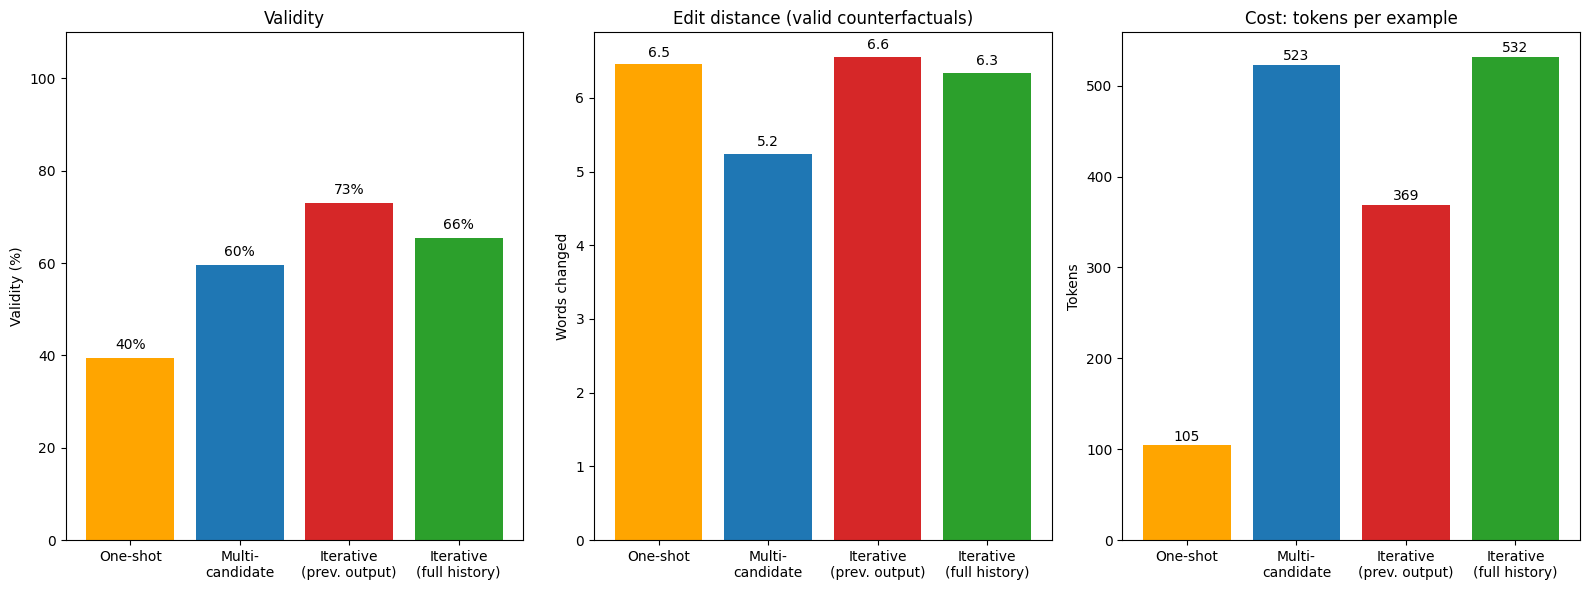

In [27]:
labels = ["One-shot", "Multi-\ncandidate", "Iterative\n(prev. output)", "Iterative\n(full history)"]
colors = ["orange", "tab:blue", "tab:red", "tab:green"]

fig, ax = plt.subplots(1, 3, figsize=(16, 6))

ax[0].bar(labels, summary["Validity (%)"], color=colors)
ax[0].set_ylabel("Validity (%)")
ax[0].set_ylim(0, 110)
ax[0].set_title("Validity")
for i, v in enumerate(summary["Validity (%)"]):
    ax[0].text(i, v + 2, f"{v:.0f}%", ha="center")

ax[1].bar(labels, summary["Edit distance (valid)"], color=colors)
ax[1].set_ylabel("Words changed")
ax[1].set_title("Edit distance (valid counterfactuals)")
for i, v in enumerate(summary["Edit distance (valid)"]):
    ax[1].text(i, v + 0.1, f"{v:.1f}", ha="center")

ax[2].bar(labels, summary["Tokens / example"], color=colors)
ax[2].set_ylabel("Tokens")
ax[2].set_title("Cost: tokens per example")
for i, v in enumerate(summary["Tokens / example"]):
    ax[2].text(i, v + 5, f"{v:.0f}", ha="center")

plt.tight_layout()
plt.savefig("comparison.png", dpi=200, bbox_inches="tight")
plt.show()

## Plot 2: effect of the retry limit
How does validity change as we allow more attempts? For iterative repair, an example counts as a success at limit *k* if a valid counterfactual was found within its first *k* attempts. Limit 1 is the same as one-shot. Multi-candidate selection is shown as a single point at its budget of K candidates.

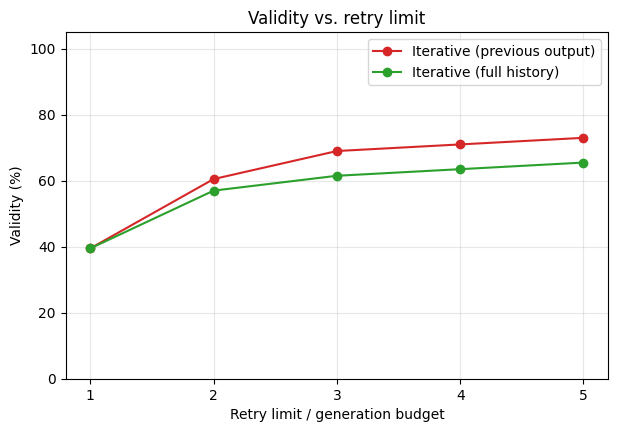

In [34]:
limits = list(range(1, MAX_ATTEMPTS + 1))

def validity_at_limit(df, k):
    return 100 * ((df["valid"]) & (df["attempts"] <= k)).mean()

plt.figure(figsize=(7, 4.5))
plt.plot(limits, [validity_at_limit(res_iter, k) for k in limits],
         marker="o", color="tab:red", label="Iterative (previous output)")
plt.plot(limits, [validity_at_limit(res_hist, k) for k in limits],
         marker="o", color="tab:green", label="Iterative (full history)")


plt.xticks(limits)
plt.xlabel("Retry limit / generation budget")
plt.ylabel("Validity (%)")
plt.ylim(0, 105)
plt.title("Validity vs. retry limit")
plt.grid(alpha=0.3)
plt.legend()
plt.savefig("retry_limit.png", dpi=200, bbox_inches="tight")
plt.show()

## Plot 3: how many examples succeed in each round
For each iterative method, this shows how many examples became valid for the first time at each attempt, and how many were still invalid after the last allowed attempt (`MAX_ATTEMPTS`).

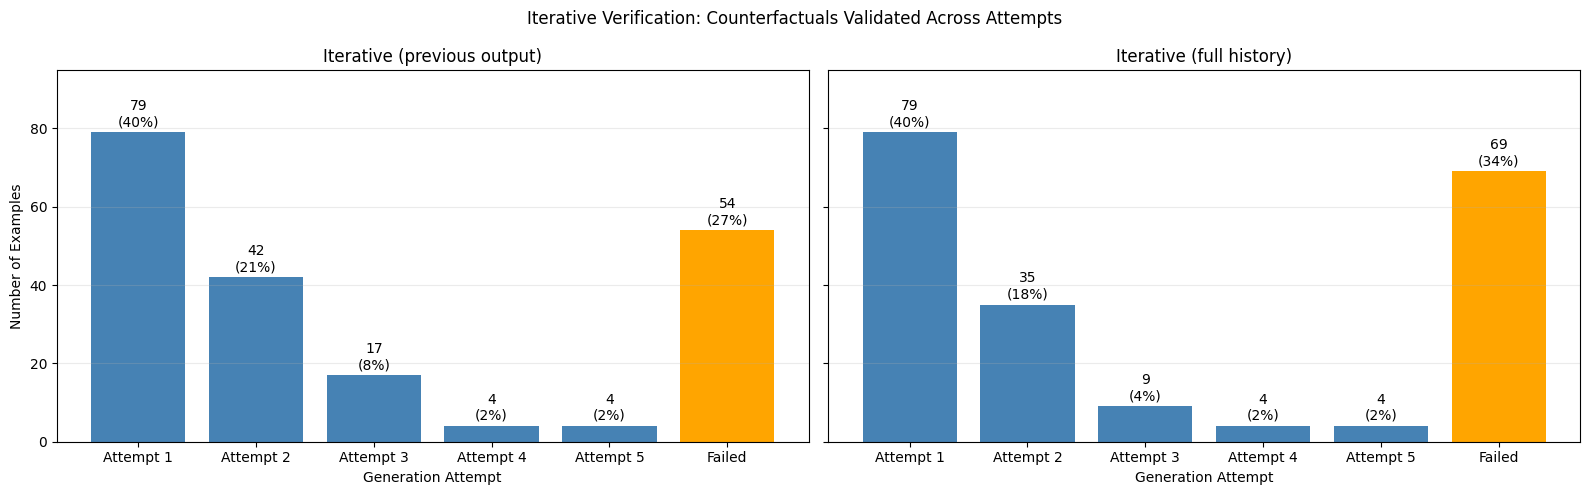

In [29]:
iter_results = {"Iterative (previous output)": res_iter, "Iterative (full history)": res_hist}
attempt_labels = [f"Attempt {i}" for i in range(1, MAX_ATTEMPTS + 1)] + ["Failed"]

panel_data = {}
for name, d in iter_results.items():
    solved = d[d["valid"]]["attempts"].value_counts().reindex(range(1, MAX_ATTEMPTS + 1), fill_value=0)
    panel_data[name] = solved.tolist() + [int((~d["valid"]).sum())]

top = max(max(v) for v in panel_data.values())

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, (name, vals) in zip(axes, panel_data.items()):
    total = sum(vals)
    bars = ax.bar(attempt_labels, vals, color=["steelblue"] * MAX_ATTEMPTS + ["orange"])
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, v + top * 0.01,
                f"{v}\n({100 * v / total:.0f}%)", ha="center", va="bottom", fontsize=10)
    ax.set_title(name)
    ax.set_xlabel("Generation Attempt")
    ax.set_ylim(0, top * 1.2)
    ax.grid(axis="y", alpha=0.25)

axes[0].set_ylabel("Number of Examples")
fig.suptitle("Iterative Verification: Counterfactuals Validated Across Attempts")
plt.tight_layout()
plt.savefig("iterative_success_progression.png", dpi=300, bbox_inches="tight")
plt.show()

# LLM-Evaluated Actionability & Feasibility

We measure whether a valid counterfactual is **actionable** using an LLM Judge that produces a single feasibility score between **0.0 and 1.0**.

To help the judge make a grounded decision, we explicitly compute and embed two quantitative metrics into the prompt:
1. **Word Edit Distance**: number of insertions, deletions, and substitutions.
2. **Cosine Similarity**: semantic similarity computed via `sentence-transformers/all-MiniLM-L6-v2`.

A counterfactual is considered **actionable** if its LLM feasibility score is **> 0.5**.

In [30]:
from sentence_transformers import SentenceTransformer

dev = "cuda" if torch.cuda.is_available() else "cpu"
embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=dev)

print("SentenceTransformer loaded successfully.")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

SentenceTransformer loaded successfully.


In [31]:
def calculate_cosine_sim(original_text, candidate_text):
    emb_o = embedder.encode(original_text, convert_to_tensor=True, normalize_embeddings=True)
    emb_c = embedder.encode(candidate_text, convert_to_tensor=True, normalize_embeddings=True)
    return float((emb_o * emb_c).sum().cpu().item())

def actionability_prompt(original, candidate, target, edit_dist, cosine_sim):
    return (
        f"Original review: {original}\n"
        f"Rewritten review: {candidate}\n"
        f"Target sentiment: {target.lower()}\n\n"
        f"Automated Metrics:\n"
        f"- Word Edit Distance: {edit_dist}\n"
        f"- Cosine Semantic Similarity: {cosine_sim:.4f}\n\n"
        "Evaluate the feasibility and actionability of this counterfactual rewrite.\n"
        "Consider whether the rewrite is natural, preserves core context, and changes only what is necessary.\n"
        "Provide a single feasibility score as a float between 0.0 and 1.0 (where 1.0 = highly actionable/feasible, 0.0 = non-feasible/unnatural).\n"
        "Output ONLY the numeric score."
    )

def evaluate_actionability_score(original, candidate, target):
    if not candidate.strip():
        return 0.0

    edit_dist = word_edit_distance(original, candidate)
    cosine_sim = calculate_cosine_sim(original, candidate)

    prompt = actionability_prompt(original, candidate, target, edit_dist, cosine_sim)

    messages = [
        {"role": "system", "content": "You are an expert evaluator of counterfactual text quality. Output only a float between 0.0 and 1.0."},
        {"role": "user", "content": prompt},
    ]

    text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(llm.device)

    with torch.no_grad():
        output = llm.generate(**inputs, max_new_tokens=10, do_sample=False, pad_token_id=tokenizer.eos_token_id)

    new_ids = output[0][inputs["input_ids"].shape[1]:]
    response = tokenizer.decode(new_ids, skip_special_tokens=True).strip()

    # Extract numerical float value from response
    match = re.search(r"0?\.\d+|1\.0|0|1", response)
    if match:
        try:
            score = float(match.group())
            return max(0.0, min(1.0, score))
        except ValueError:
            return 0.0
    return 0.0

def add_actionability_metrics(df):
    df = df.copy()
    df["candidate"] = df["candidate"].fillna("").astype(str)

    # Compute Cosine Similarity for the entire batch
    emb_o = embedder.encode(df["original"].tolist(), convert_to_tensor=True, normalize_embeddings=True, batch_size=64)
    emb_c = embedder.encode(df["candidate"].tolist(), convert_to_tensor=True, normalize_embeddings=True, batch_size=64)
    df["cosine_sim"] = (emb_o * emb_c).sum(dim=1).cpu().numpy()

    # Evaluate LLM Actionability score example by example
    scores = []
    for o, c, t in tqdm(zip(df["original"], df["candidate"], df["target_label"]), total=len(df), desc="Scoring Actionability"):
        scores.append(evaluate_actionability_score(o, c, t))

    df["actionability_score"] = scores
    df["actionable"] = (df["valid"]) & (df["actionability_score"] > ACTIONABILITY_THRESHOLD)
    return df

In [32]:
results_q = {}
for name, df in results.items():
    results_q[name] = add_actionability_metrics(df)

# Save combined dataset
pd.concat([q.assign(method=name) for name, q in results_q.items()]).to_csv("all_methods_actionability.csv", index=False)

# Display summary statistics of scores for valid counterfactuals
valid_cf_summary = pd.concat([q[q["valid"]] for q in results_q.values()])
valid_cf_summary[["edit_distance", "cosine_sim", "actionability_score"]].describe().round(3)

Scoring Actionability:   0%|          | 0/200 [00:00<?, ?it/s]

Scoring Actionability:   0%|          | 0/200 [00:00<?, ?it/s]

Scoring Actionability:   0%|          | 0/200 [00:00<?, ?it/s]

Scoring Actionability:   0%|          | 0/200 [00:00<?, ?it/s]

,edit_distance,cosine_sim,actionability_score
count,475.000,475.000,475.000
mean,6.149,0.856,0.514
std,5.001,0.124,0.388
min,1.000,0.141,0.000
25%,2.000,0.811,0.000
50%,5.000,0.883,0.750
75%,8.000,0.949,0.850
max,26.000,0.995,1.000


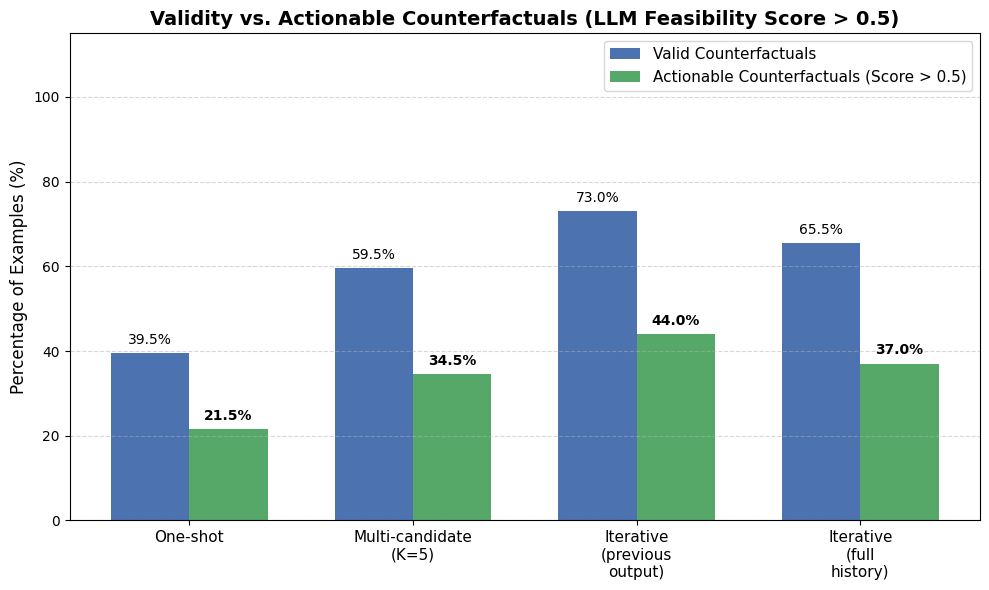

In [33]:
method_names = list(results_q.keys())
valid_rates = [100 * df["valid"].mean() for df in results_q.values()]
actionable_rates = [100 * (df["actionable"]).mean() for df in results_q.values()]

x = np.arange(len(method_names))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(x - width/2, valid_rates, width, label="Valid Counterfactuals", color="#4C72B0")
bars2 = ax.bar(x + width/2, actionable_rates, width, label="Actionable Counterfactuals (Score > 0.5)", color="#55A868")

ax.set_ylabel("Percentage of Examples (%)", fontsize=12)
ax.set_title("Validity vs. Actionable Counterfactuals (LLM Feasibility Score > 0.5)", fontsize=14, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels([m.replace(" ", "\n") for m in method_names], fontsize=11)
ax.set_ylim(0, 115)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend(fontsize=11)

# Annotate bar values
for bar in bars1:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 1.5, f"{yval:.1f}%", ha="center", va="bottom", fontsize=10)

for bar in bars2:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 1.5, f"{yval:.1f}%", ha="center", va="bottom", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.savefig("final_actionable_counterfactuals_plot.png", dpi=300, bbox_inches="tight")
plt.show()

# References
1. Dehghanighobadi, Z., Fischer, A., Zafar, M. B. (2025). *Can LLMs Explain Themselves Counterfactually?* EMNLP 2025, 7787–7815.
2. Qwen2.5-3B-Instruct – https://huggingface.co/Qwen/Qwen2.5-3B-Instruct
3. DistilBERT SST-2 classifier – https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english
4. GLUE / SST-2 – https://huggingface.co/datasets/nyu-mll/glue
5. LangGraph – https://langchain-ai.github.io/langgraph/
6. Sentence-Transformers `all-MiniLM-L6-v2` – https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2
7. Levenshtein distance – https://en.wikipedia.org/wiki/Levenshtein_distance
8. Wachter, S., Mittelstadt, B., Russell, C. (2017). *Counterfactual Explanations without Opening the Black Box.* Harvard Journal of Law & Technology.
9. Ustun, B., Spangher, A., Liu, Y. (2019). *Actionable Recourse in Linear Classification.* FAT* 2019.
10. Mothilal, R. K., Sharma, A., Tan, C. (2020). *Explaining Machine Learning Classifiers through Diverse Counterfactual Explanations.* FAT* 2020.
11. Karimi, A.-H., Barthe, G., Schölkopf, B., Valera, I. (2022). *A Survey of Algorithmic Recourse: Contrastive Explanations and Consequential Recommendations.* ACM Computing Surveys.
12. Radford, A. et al. (2019). *Language Models are Unsupervised Multitask Learners* (GPT-2).
13. Zheng, L. et al. (2023). *Judging LLM-as-a-Judge with MT-Bench and Chatbot Arena.* NeurIPS 2023.